# Rabi Oscillations and the Cramér–Rao Bound

A driven two-level atom is excited with probability
$P(t;\Omega,\Delta) = \frac{\Omega^2}{W^2}\sin^2(Wt/2)$, $W=\sqrt{\Omega^2+\Delta^2}$.
We measure at $t_k = 0.25k$ ($k=1..24$), $N=100$ shots each, so $n_k\sim\mathrm{Binomial}(N,P_k)$.

Three estimators of $(\Omega,\Delta)$ from the same data:
1. **The Cramér–Rao bound** — the best any unbiased estimator can do, from the Fisher information.
2. **Maximum likelihood** — grid search + Fisher scoring.
3. **A neural network** trained on simulated experiments.

$P$ depends on $\Delta$ only through $u=\Delta^2$, so we work in $(\Omega, u)$.

In [1]:
import numpy as np, matplotlib.pyplot as plt
import rabi, rabinet
from rabi import T, N_SHOTS

CHECKS = []
def check(name, ok, detail=''):
    CHECKS.append((name, bool(ok)))
    print(f"CHECK {name}: {'PASS' if ok else 'FAIL'}   {detail}")

## One experiment, three answers

One simulated dataset at $(\Omega,\Delta)=(1.5,0.5)$, with binomial error bars $\sqrt{P(1-P)/N}$.

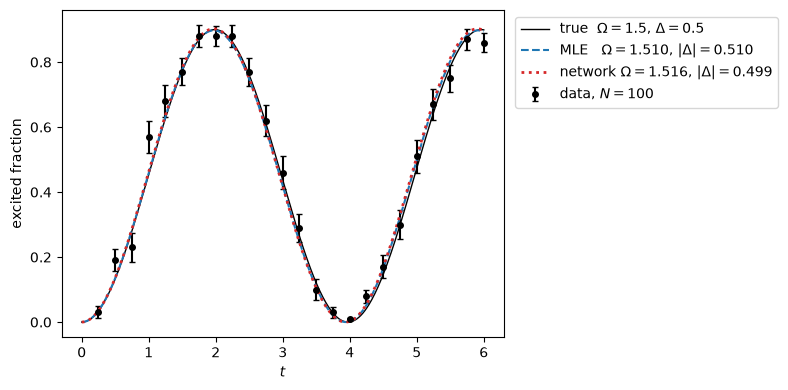

In [2]:
OM0, DE0 = 1.5, 0.5
n_one = rabi.simulate(OM0, DE0**2, 1, np.random.default_rng(1))[0]
tt = np.linspace(0, T[-1], 400)

plt.figure(figsize=(8, 4))
plt.errorbar(T, n_one / N_SHOTS, np.sqrt(rabi.prob(OM0, DE0**2) * (1 - rabi.prob(OM0, DE0**2)) / N_SHOTS),
             fmt='o', color='k', ms=4, capsize=2, label='data, $N=100$')
plt.plot(tt, rabi.prob(OM0, DE0**2, tt), 'k-', lw=1, label=f'true  $\\Omega={OM0}$, $\\Delta={DE0}$')
Om_m, u_m = (x[0] for x in rabi.mle(n_one))
plt.plot(tt, rabi.prob(Om_m, u_m, tt), 'C0--', label=f'MLE   $\\Omega={Om_m:.3f}$, $|\\Delta|={np.sqrt(max(u_m, 0)):.3f}$')
net, loss_hist = rabinet.get_net()          # trains once (~40 s), then loads the cached weights
Om_n, u_n, _ = (x[0] for x in rabinet.predict(net, n_one))
plt.plot(tt, rabi.prob(Om_n, u_n, tt), 'C3:', lw=2, label=f'network $\\Omega={Om_n:.3f}$, $|\\Delta|={np.sqrt(max(u_n, 0)):.3f}$')
plt.xlabel('$t$'); plt.ylabel('excited fraction')
plt.legend(loc='upper left', bbox_to_anchor=(1.01, 1)); plt.tight_layout(); plt.show()

## Step 1 — The forward model and the bound

Fisher information for binomial counts:
$I_{ij}=\sum_k \frac{N}{P_k(1-P_k)}\partial_iP_k\,\partial_jP_k$, and the CRB is $\sqrt{\mathrm{diag}\,I^{-1}}$.
First the analytic derivatives against central finite differences.

In [3]:
h = 1e-6
worst = 0
for Om, u in [(1.5, 0.25), (1.0, 0.64), (2.0, 0.0), (1.2, 0.9)]:
    fd = np.stack([(rabi.prob(Om + h, u) - rabi.prob(Om - h, u)) / (2 * h),
                   (rabi.prob(Om, u + h) - rabi.prob(Om, u - h)) / (2 * h)])
    worst = max(worst, np.abs(fd - rabi.grad_prob(Om, u)).max() / np.abs(fd).max())
check('analytic gradient vs finite differences', worst < 1e-6, f'max rel err = {worst:.1e}')

CHECK analytic gradient vs finite differences: PASS   max rel err = 1.8e-10


The bound at the reference points. $\sigma_\Delta = \sigma_u / (2\Delta)$ blows up as $\Delta\to0$,
because $\partial P/\partial\Delta=0$ there: the sign of the detuning is invisible, and so is a small detuning.
$\sigma_u$ stays finite.

In [4]:
ref = {(1.5, 0.5): (0.01115, 0.03085), (1.5, 0.05): (0.00662, 0.13204),
       (1.0, 0.8): (0.01556, 0.01845), (2.0, 0.5): (0.01357, 0.04585)}
print(f"{'(Om, De)':>12} {'sig_Om':>9} {'sig_De':>9} {'sig_u':>9}")
ok = True
for (Om, De), (sO, sD) in ref.items():
    s_Om, s_u = rabi.crb(Om, De**2)
    print(f"{str((Om, De)):>12} {s_Om:9.5f} {s_u/(2*De):9.5f} {s_u:9.5f}")
    ok &= abs(s_Om - sO) < 1e-5 and abs(s_u / (2 * De) - sD) < 1e-5
check('CRB reference values', ok)

def I_DeDe(Om, De):   # chain rule: dP/dDe = 2 De dP/du
    p, g = rabi.prob(Om, De**2), 2 * De * rabi.grad_prob(Om, De**2)[1]
    return (N_SHOTS / (p * (1 - p)) * g**2).sum()
I_uu = rabi.fisher(1.5, 0.0)[1, 1]
check('Fisher info for Delta vanishes at Delta=0, for u it does not',
      I_DeDe(1.5, 0.0) == 0 and I_uu > 0,
      f'I_DeDe(0) = {I_DeDe(1.5, 0.0)},  I_uu(0) = {I_uu:.0f},  sigma_u(De=0) = {rabi.crb(1.5, 0.0)[1]:.5f}')

r = rabi.crb(1.5, 0.25, N=400) / rabi.crb(1.5, 0.25, N=100)
check('CRB scales as 1/sqrt(N)', np.allclose(r, 0.5, atol=1e-12), f'ratio N=400 / N=100 = {r}')

    (Om, De)    sig_Om    sig_De     sig_u
  (1.5, 0.5)   0.01115   0.03085   0.03085
 (1.5, 0.05)   0.00662   0.13204   0.01320
  (1.0, 0.8)   0.01556   0.01845   0.02952
  (2.0, 0.5)   0.01357   0.04585   0.04585
CHECK CRB reference values: PASS   
CHECK Fisher info for Delta vanishes at Delta=0, for u it does not: PASS   I_DeDe(0) = 0.0,  I_uu(0) = 8344,  sigma_u(De=0) = 0.01240
CHECK CRB scales as 1/sqrt(N): PASS   ratio N=400 / N=100 = [0.5 0.5]


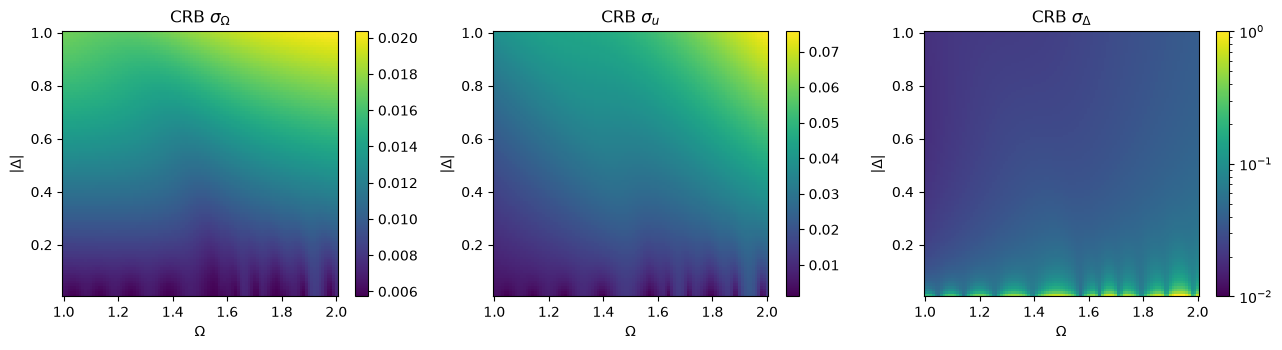

In [5]:
# The bound over the whole prior
Om_g, De_g = np.meshgrid(np.linspace(1, 2, 101), np.linspace(0.01, 1, 100), indexing='ij')
S = rabi.crb(Om_g, De_g**2)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for a, z, title, kw in zip(ax, [S[..., 0], S[..., 1], S[..., 1] / (2 * De_g)],
                           [r'CRB $\sigma_\Omega$', r'CRB $\sigma_u$', r'CRB $\sigma_\Delta$'],
                           [{}, {}, dict(norm=plt.matplotlib.colors.LogNorm(0.01, 1))]):
    im = a.pcolormesh(Om_g, De_g, z, shading='auto', **kw)
    plt.colorbar(im, ax=a); a.set_title(title); a.set_xlabel(r'$\Omega$'); a.set_ylabel(r'$|\Delta|$')
plt.tight_layout(); plt.show()

$\sigma_\Omega$ and $\sigma_u$ are smooth and of order $10^{-2}$ everywhere. $\sigma_\Delta$ diverges along the
bottom edge: near zero detuning the experiment cannot tell $\Delta$ from $0$, even though it measures
$\Delta^2$ just fine.

## Step 3 — Maximum likelihood

$\ell=\sum_k[n_k\ln P_k+(N-n_k)\ln(1-P_k)]$. Along $\Omega$ it has several local maxima — a slightly
different frequency lines up with a different set of fringes — so a local optimizer from a bad start
lands in the wrong one. We start from a coarse grid in $(\Omega,|\Delta|)$ and refine with Fisher scoring,
$\theta\leftarrow\theta+I(\theta)^{-1}\nabla\ell$, which reuses the Step 1 code.

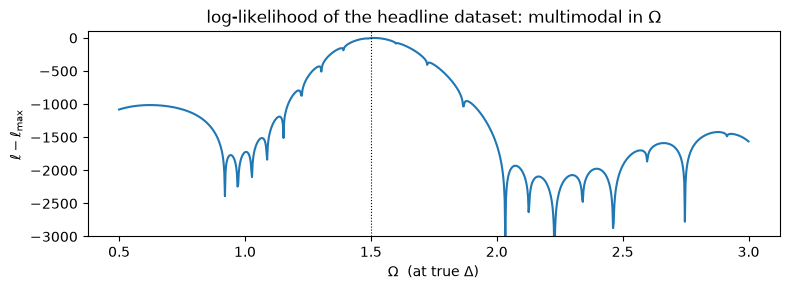

In [6]:
Om_line = np.linspace(0.5, 3, 1000)
plt.figure(figsize=(8, 3))
plt.plot(Om_line, rabi.loglik(n_one, Om_line, DE0**2) - rabi.loglik(n_one, Om_m, u_m))
plt.axvline(OM0, color='k', lw=0.8, ls=':'); plt.ylim(-3000, 100)
plt.xlabel(r'$\Omega$  (at true $\Delta$)'); plt.ylabel(r'$\ell - \ell_{\max}$')
plt.title('log-likelihood of the headline dataset: multimodal in $\\Omega$'); plt.tight_layout(); plt.show()

**At (1.5, 0.5): does the MLE sit on the bound?** 2000 simulated datasets. The Monte Carlo error on a
standard deviation estimated from $M$ samples is $\sigma/\sqrt{2M}\approx1.6\%$; on a mean it is $\sigma/\sqrt M$.

Om: mean = 1.50015 (true 1.5),  std = 0.01144,  CRB = 0.01115
CHECK MLE std / CRB = 1 for Om at (1.5, 0.5): PASS   ratio = 1.026 +- 0.016
CHECK MLE unbiased for Om at (1.5, 0.5): PASS   bias = +0.00015 +- 0.00026
u: mean = 0.24836 (true 0.25),  std = 0.03108,  CRB = 0.03085
CHECK MLE std / CRB = 1 for u at (1.5, 0.5): PASS   ratio = 1.007 +- 0.016
CHECK MLE unbiased for u at (1.5, 0.5): PASS   bias = -0.00164 +- 0.00070


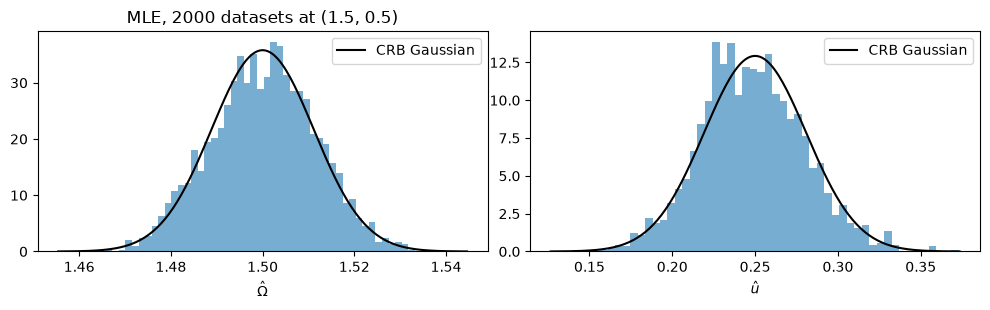

In [7]:
M = 2000
n_A = rabi.simulate(OM0, DE0**2, M, np.random.default_rng(2))
Om_A, u_A = rabi.mle(n_A)
crb_A = rabi.crb(OM0, DE0**2)
for name, est, true, s in [('Om', Om_A, OM0, crb_A[0]), ('u', u_A, DE0**2, crb_A[1])]:
    ratio, err = est.std() / s, 1 / np.sqrt(2 * M)
    bias, bias_err = est.mean() - true, est.std() / np.sqrt(M)
    print(f"{name}: mean = {est.mean():.5f} (true {true}),  std = {est.std():.5f},  CRB = {s:.5f}")
    check(f'MLE std / CRB = 1 for {name} at (1.5, 0.5)', abs(ratio - 1) < 3 * err, f'ratio = {ratio:.3f} +- {err:.3f}')
    check(f'MLE unbiased for {name} at (1.5, 0.5)', abs(bias) < 3 * bias_err, f'bias = {bias:+.5f} +- {bias_err:.5f}')

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for a, est, true, s, lab in [(ax[0], Om_A, OM0, crb_A[0], r'$\hat\Omega$'), (ax[1], u_A, DE0**2, crb_A[1], r'$\hat u$')]:
    a.hist(est, 50, density=True, alpha=0.6)
    x = np.linspace(true - 4 * s, true + 4 * s, 200)
    a.plot(x, np.exp(-(x - true)**2 / (2 * s**2)) / np.sqrt(2 * np.pi * s**2), 'k', label='CRB Gaussian')
    a.set_xlabel(lab); a.legend()
ax[0].set_title('MLE, 2000 datasets at (1.5, 0.5)'); plt.tight_layout(); plt.show()

**The first apparent violation, at (1.5, 0.05).** Here $\sigma_u=0.0132$ is five times the true
$u=0.0025$, so the data cannot keep $\hat u$ away from the physical boundary $u\ge0$. (For $u<0$ the
amplitude $\Omega^2/W^2$ exceeds 1 and $P$ stops being a probability, so the MLE is constrained there.)
About half the datasets put $\hat u$ exactly at 0. Both $\hat u$ and $|\hat\Delta|=\sqrt{\hat u}$ then come out
*below* their "bounds". The theorem is not broken: an estimator that respects $u\ge0$ is biased upward
next to the boundary, and the CRB only constrains unbiased estimators. The bound means something only
where $\sigma_u\ll u$, as at $\Delta=0.5$.

*A note on how we found this:* a first version let $\hat u$ go negative. Its histogram came out bimodal,
with a spurious peak at $u<0$ where the clipped $P>1$ made a fake maximum.

fraction of datasets with u_hat = 0: 0.47
|De|: rmse = 0.0618,  CRB = 0.1320,  rmse/CRB = 0.47,  bias = +0.0050 +- 0.0014
CHECK |De| MLE "beats" its CRB at (1.5, 0.05): PASS   rmse / CRB = 0.47
CHECK ...because |De| MLE is biased upward: PASS   bias / err = 3.6
   u: rmse = 0.0108,  CRB = 0.0132,  rmse/CRB = 0.82,  bias = +0.0043 +- 0.0002
CHECK u MLE "beats" its CRB at (1.5, 0.05): PASS   rmse / CRB = 0.82
CHECK ...because u MLE is biased upward: PASS   bias / err = 19.5


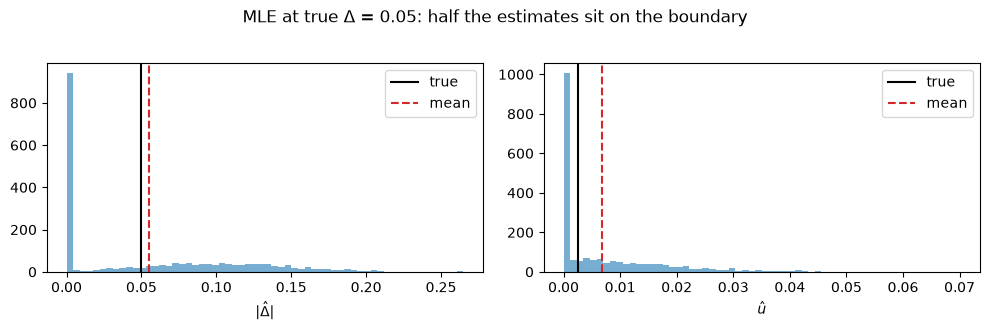

In [8]:
DE_B = 0.05
n_B = rabi.simulate(OM0, DE_B**2, M, np.random.default_rng(3))
Om_B, u_B = rabi.mle(n_B)
De_B = np.sqrt(u_B)
s_Om_B, s_u_B = rabi.crb(OM0, DE_B**2)
s_De_B = s_u_B / (2 * DE_B)
print(f"fraction of datasets with u_hat = 0: {(u_B == 0).mean():.2f}")
for name, est, true, s in [('|De|', De_B, DE_B, s_De_B), ('u', u_B, DE_B**2, s_u_B)]:
    rmse, bias, bias_err = np.sqrt(((est - true)**2).mean()), est.mean() - true, est.std() / np.sqrt(M)
    print(f"{name:>4}: rmse = {rmse:.4f},  CRB = {s:.4f},  rmse/CRB = {rmse/s:.2f},  bias = {bias:+.4f} +- {bias_err:.4f}")
    check(f'{name} MLE "beats" its CRB at (1.5, 0.05)', rmse < s * (1 - 3 / np.sqrt(2 * M)), f'rmse / CRB = {rmse/s:.2f}')
    check(f'...because {name} MLE is biased upward', bias > 3 * bias_err, f'bias / err = {bias/bias_err:.1f}')

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for a, est, true, lab in [(ax[0], De_B, DE_B, r'$|\hat\Delta|$'), (ax[1], u_B, DE_B**2, r'$\hat u$')]:
    a.hist(est, 60, alpha=0.6); a.axvline(true, color='k', label='true'); a.axvline(est.mean(), color='C3', ls='--', label='mean')
    a.set_xlabel(lab); a.legend()
fig.suptitle(f'MLE at true $\\Delta$ = {DE_B}: half the estimates sit on the boundary', y=1.02)
plt.tight_layout(); plt.show()

## Step 4 — The network

MLP: 24 inputs $n_k/N$ → 128 tanh → 128 tanh → 3 outputs $(\hat\Omega,\hat u,\hat\Delta)$, the last one **signed**.
MSE loss, Adam $10^{-3}$ with cosine decay, 20000 steps of 512 fresh draws from the prior
$\Omega\sim U[1,2]$, $\Delta\sim U[-1,1]$. The training set is unlimited, so there is nothing to overfit.

**Prediction before training.** The MSE-optimal output is the posterior mean $E[\theta\mid n]$. Given the
data, $+\Delta$ and $-\Delta$ are exactly equally likely, so the signed head should learn to output $\approx0$
for every input.

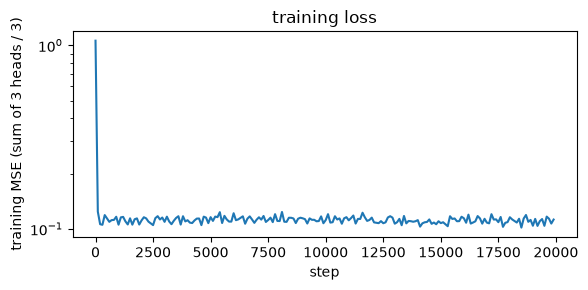

In [9]:
plt.figure(figsize=(6, 3))
plt.semilogy(np.arange(len(loss_hist)) * 100, loss_hist)
plt.xlabel('step'); plt.ylabel('training MSE (sum of 3 heads / 3)'); plt.title('training loss'); plt.tight_layout(); plt.show()

In [10]:
test_pts = [(1.5, 0.5), (1.5, -0.5), (1.5, 0.05), (1.0, 0.8), (2.0, 0.5), (1.02, 0.5)]
rng = np.random.default_rng(4)
print(f"{'(Om, De)':>12} {'<Om_hat>':>9} {'<u_hat>':>9} {'true u':>7} {'<De_hat>':>9} {'std De_hat':>10}")
worst = 0
for Om, De in test_pts:
    o, u, d = rabinet.predict(net, rabi.simulate(Om, De**2, M, rng))
    print(f"{str((Om, De)):>12} {o.mean():9.4f} {u.mean():9.4f} {De**2:7.4f} {d.mean():9.4f} {d.std():10.4f}")
    worst = max(worst, abs(d.mean()))
check('signed Delta head outputs ~0 everywhere (sign is invisible)', worst < 0.01, f'max |<De_hat>| = {worst:.4f}')

    (Om, De)  <Om_hat>   <u_hat>  true u  <De_hat> std De_hat
  (1.5, 0.5)    1.5004    0.2516  0.2500   -0.0026     0.0006
 (1.5, -0.5)    1.5006    0.2507  0.2500   -0.0026     0.0006
 (1.5, 0.05)    1.5020    0.0048  0.0025   -0.0021     0.0005


  (1.0, 0.8)    1.0051    0.6473  0.6400   -0.0007     0.0007
  (2.0, 0.5)    2.0034    0.2692  0.2500   -0.0018     0.0003
 (1.02, 0.5)    1.0281    0.2496  0.2500    0.0011     0.0007
CHECK signed Delta head outputs ~0 everywhere (sign is invisible): PASS   max |<De_hat>| = 0.0026


**At (1.5, 0.5), on the same 2000 datasets the MLE saw.**

             std Om   /CRB   bias Om      std u   /CRB    bias u
       CRB  0.01115   1.00              0.03085   1.00
       MLE  0.01144   1.03  +0.00015    0.03108   1.01  -0.00164
   network  0.01295   1.16  +0.00059    0.03209   1.04  +0.00033
CHECK network does not beat the CRB in the interior (Om): PASS   ratio = 1.161
CHECK network does not beat the CRB in the interior (u): PASS   ratio = 1.040
CHECK network within 25% of the CRB in the interior: PASS   


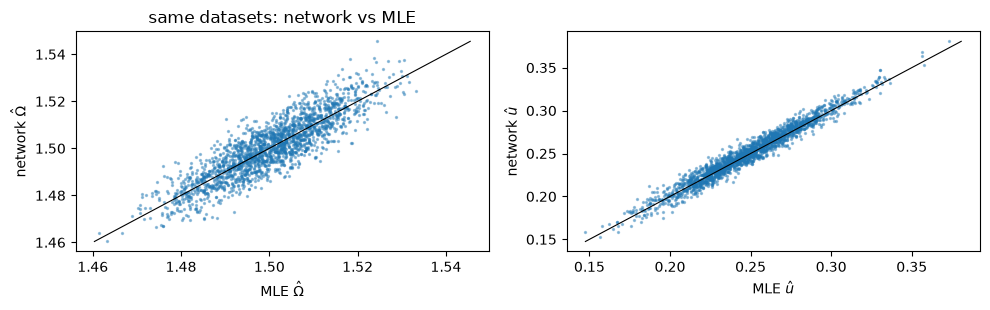

correlation network vs MLE: 0.876 0.978


In [11]:
Om_N, u_N, _ = rabinet.predict(net, n_A)
print(f"{'':>10} {'std Om':>8} {'/CRB':>6} {'bias Om':>9}   {'std u':>8} {'/CRB':>6} {'bias u':>9}")
for name, o, u in [('CRB', None, None), ('MLE', Om_A, u_A), ('network', Om_N, u_N)]:
    if o is None:
        print(f"{name:>10} {crb_A[0]:8.5f} {1:6.2f} {'':>9}   {crb_A[1]:8.5f} {1:6.2f}"); continue
    print(f"{name:>10} {o.std():8.5f} {o.std()/crb_A[0]:6.2f} {o.mean()-OM0:+9.5f}   "
          f"{u.std():8.5f} {u.std()/crb_A[1]:6.2f} {u.mean()-DE0**2:+9.5f}")
err = 1 / np.sqrt(2 * M)
check('network does not beat the CRB in the interior (Om)', Om_N.std() / crb_A[0] > 1 - 3 * err, f'ratio = {Om_N.std()/crb_A[0]:.3f}')
check('network does not beat the CRB in the interior (u)', u_N.std() / crb_A[1] > 1 - 3 * err, f'ratio = {u_N.std()/crb_A[1]:.3f}')
check('network within 25% of the CRB in the interior', max(Om_N.std() / crb_A[0], u_N.std() / crb_A[1]) < 1.25)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for a, m, nn, true, lab in [(ax[0], Om_A, Om_N, OM0, r'$\hat\Omega$'), (ax[1], u_A, u_N, DE0**2, r'$\hat u$')]:
    a.scatter(m, nn, s=2, alpha=0.4); lim = [min(m.min(), nn.min()), max(m.max(), nn.max())]
    a.plot(lim, lim, 'k', lw=0.8); a.set_xlabel(f'MLE {lab}'); a.set_ylabel(f'network {lab}')
ax[0].set_title('same datasets: network vs MLE'); plt.tight_layout(); plt.show()
print('correlation network vs MLE:', np.corrcoef(Om_A, Om_N)[0, 1].round(3), np.corrcoef(u_A, u_N)[0, 1].round(3))

The network is close to the bound but not on it, and unbiased in the interior. The table above also
shows it pulling estimates inward at the edges of the prior: at $\Omega=1.02$ it reports $1.028$, and at
$(2.0,0.5)$ it reports $u=0.269$ against $0.25$. Step 5 maps this over the whole prior.

## Step 5 — Where the network is good, and where it only looks good

On an $11\times11$ grid covering the prior ($|\Delta|\ge0$ suffices by symmetry), 400 datasets per point, we
compute for both estimators the efficiency $\mathrm{CRB}^2/\mathrm{MSE}$ and split
$\mathrm{MSE}=\mathrm{bias}^2+\mathrm{variance}$. Efficiency 1 means "on the bound"; above 1 means the
estimator beats the bound, which only a biased estimator can do.

In [12]:
M5 = 400
Om_grid, De_grid = np.linspace(1, 2, 11), np.linspace(0, 1, 11)
shape = (len(Om_grid), len(De_grid))
R = {k: np.zeros(shape + (2,)) for k in ['crb', 'bias_mle', 'var_mle', 'bias_net', 'var_net']}
rng = np.random.default_rng(5)
ll_gap = -np.inf      # max over datasets of  loglik(truth) - loglik(MLE);  must be <= 0
for i, Om in enumerate(Om_grid):
    for j, De in enumerate(De_grid):
        n = rabi.simulate(Om, De**2, M5, rng)
        true = np.array([Om, De**2])
        R['crb'][i, j] = rabi.crb(Om, De**2)
        mle_est = np.stack(rabi.mle(n), 1)
        ll_gap = max(ll_gap, (rabi.loglik(n, Om, De**2) - rabi.loglik(n, *mle_est.T)).max())
        for tag, est in [('mle', mle_est), ('net', np.stack(rabinet.predict(net, n)[:2], 1))]:
            R['bias_' + tag][i, j] = est.mean(0) - true
            R['var_' + tag][i, j] = est.var(0)
eff = {tag: R['crb']**2 / (R['bias_' + tag]**2 + R['var_' + tag]) for tag in ['mle', 'net']}
check('MLE likelihood >= likelihood at the truth, on every dataset', ll_gap <= 0,
      f'{len(Om_grid) * len(De_grid) * M5} datasets, max gap = {ll_gap:.2e}')

CHECK MLE likelihood >= likelihood at the truth, on every dataset: PASS   48400 datasets, max gap = -1.16e-07


*How we found a bug with this check:* the first version of the MLE took undamped Fisher-scoring steps.
On one dataset at $(1.1, 0.5)$ a step overshot from the right grid start to $\Omega=-0.90$ (where $P$ is the
same, since it depends on $\Omega^2$), with a likelihood far *below* the truth's. That single dataset made
the MLE efficiency map show a dark square. Step halving fixed it, and the check above now guards it.

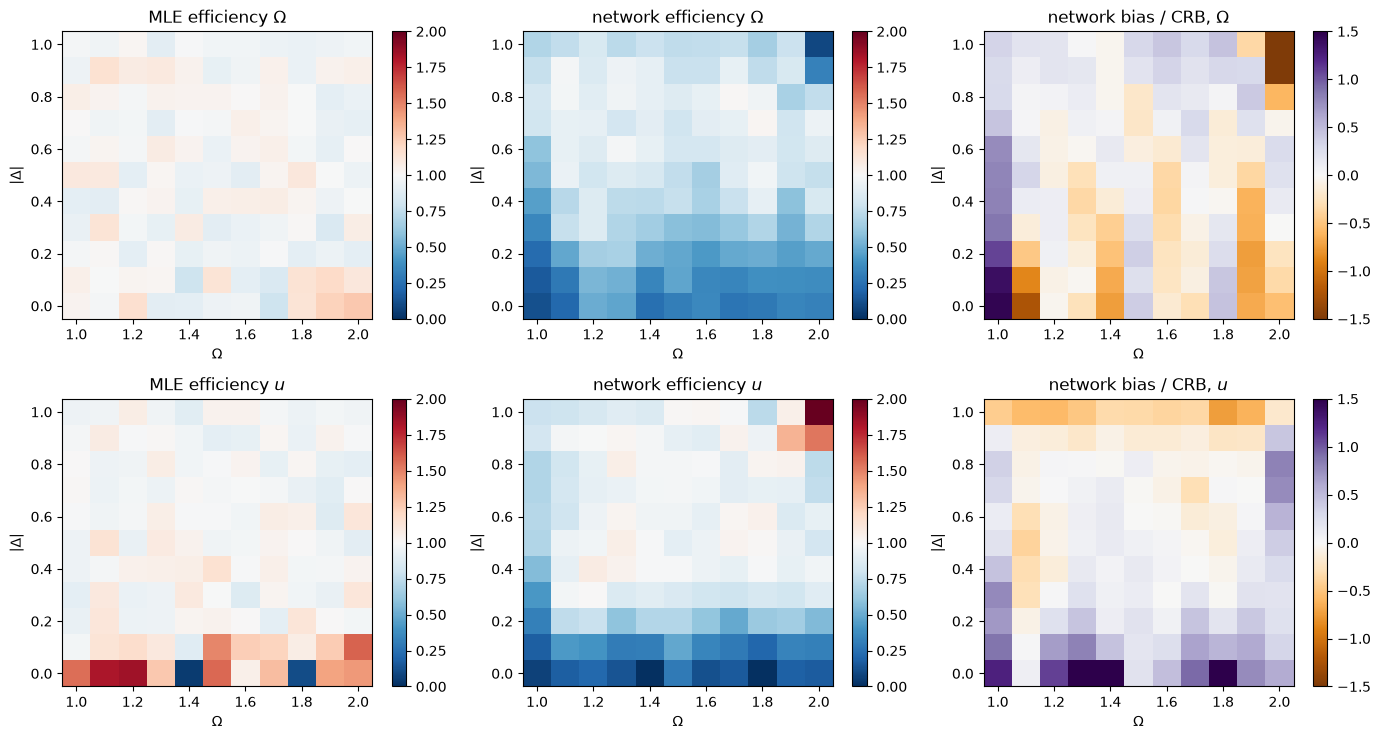

In [13]:
fig, ax = plt.subplots(2, 3, figsize=(14, 7.5))
ext = dict(shading='nearest')
for r, (p, lab) in enumerate([(0, r'\Omega'), (1, 'u')]):
    for c, (z, title, kw) in enumerate([
            (eff['mle'][..., p], f'MLE efficiency ${lab}$', dict(cmap='RdBu_r', vmin=0, vmax=2)),
            (eff['net'][..., p], f'network efficiency ${lab}$', dict(cmap='RdBu_r', vmin=0, vmax=2)),
            (R['bias_net'][..., p] / R['crb'][..., p], f'network bias / CRB, ${lab}$', dict(cmap='PuOr', vmin=-1.5, vmax=1.5))]):
        im = ax[r, c].pcolormesh(Om_grid, De_grid, z.T, **ext, **kw)
        plt.colorbar(im, ax=ax[r, c]); ax[r, c].set_title(title)
        ax[r, c].set_xlabel(r'$\Omega$'); ax[r, c].set_ylabel(r'$|\Delta|$')
plt.tight_layout(); plt.show()

**The second apparent violation.** Wherever the network's *variance alone* is below $\mathrm{CRB}^2$ by more
than the Monte Carlo error ($\sqrt{2/M}\approx7\%$ on a variance), look for the bias that pays for it.

In [14]:
err_var = np.sqrt(2 / M5)
print(f"{'(Om, |De|)':>14} {'param':>5} {'var/CRB^2':>10} {'bias/CRB':>9} {'bias/err':>9}")
all_biased, count = True, 0
for i, Om in enumerate(Om_grid):
    for j, De in enumerate(De_grid):
        for p, name in [(0, 'Om'), (1, 'u')]:
            v = R['var_net'][i, j, p] / R['crb'][i, j, p]**2
            if v < 1 - 3 * err_var:
                b = R['bias_net'][i, j, p]
                z = b / np.sqrt(R['var_net'][i, j, p] / M5)
                count += 1; all_biased &= abs(z) > 3
                print(f"{f'({Om:.1f}, {De:.1f})':>14} {name:>5} {v:10.2f} {b / R['crb'][i, j, p]:+9.2f} {z:+9.1f}")
print(f"\n{count} (point, parameter) pairs with variance below the bound")
check('every sub-CRB variance of the network comes with significant bias', all_biased and count > 0)

interior = np.ix_(range(2, 9), range(3, 10))
for p, name in [(0, 'Om'), (1, 'u')]:
    print(f"median efficiency in the interior, {name}:  MLE {np.median(eff['mle'][interior][..., p]):.2f}"
          f"   network {np.median(eff['net'][interior][..., p]):.2f}")

    (Om, |De|) param  var/CRB^2  bias/CRB  bias/err
    (1.9, 0.9)     u       0.69     -0.22      -5.3
    (1.9, 1.0)     u       0.55     -0.63     -17.0
    (2.0, 0.7)     u       0.73     +0.77     +18.0
    (2.0, 0.8)     u       0.70     +0.81     +19.5
    (2.0, 0.9)     u       0.47     +0.43     +12.5
    (2.0, 1.0)     u       0.35     -0.20      -6.6

6 (point, parameter) pairs with variance below the bound
CHECK every sub-CRB variance of the network comes with significant bias: PASS   
median efficiency in the interior, Om:  MLE 1.01   network 0.86
median efficiency in the interior, u:  MLE 0.99   network 0.97


**The surprise: the network is weak at small $|\Delta|$.** The efficiency maps show the network dropping to
$\sim0.3$ along the bottom edge, where the MLE is fine. A profile at $\Omega=1.5$ shows why: the network's
error is flat at about $0.011$ while the bound keeps falling.

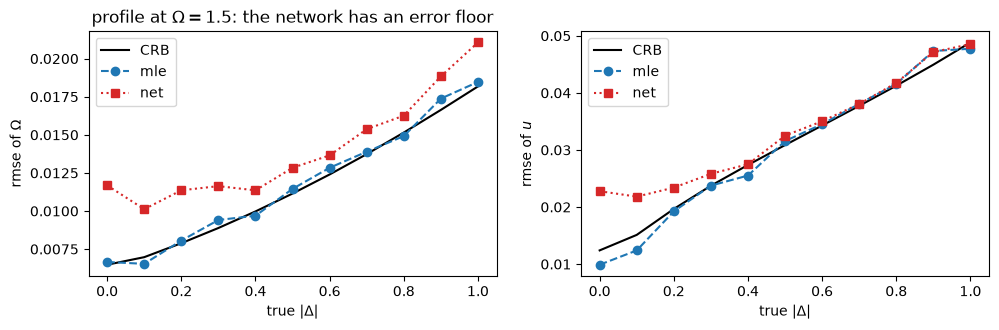

In [15]:
i15 = 5   # Om_grid[5] = 1.5
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for a, p, lab in [(ax[0], 0, r'$\Omega$'), (ax[1], 1, '$u$')]:
    a.plot(De_grid, R['crb'][i15, :, p], 'k-', label='CRB')
    for tag, sty in [('mle', 'C0o--'), ('net', 'C3s:')]:
        a.plot(De_grid, np.sqrt(R['bias_' + tag][i15, :, p]**2 + R['var_' + tag][i15, :, p]), sty, label=tag)
    a.set_xlabel(r'true $|\Delta|$'); a.set_ylabel(f'rmse of {lab}'); a.legend()
ax[0].set_title(r'profile at $\Omega=1.5$: the network has an error floor'); plt.tight_layout(); plt.show()

**Hypothesis: the floor is the network's capacity, not the problem.** Test, run offline because it takes
~8 min (`bignet_check.py`): 3 hidden layers of 256, 60000 steps of batch 1024. rmse of $\hat\Omega$ at $\Omega=1.5$,
2000 datasets per row:

| $\Delta$ | CRB | small net (this notebook) | big net | MLE |
|---|---|---|---|---|
| 0.0 | 0.0065 | 0.0109 | 0.0078 | 0.0064 |
| 0.1 | 0.0070 | 0.0109 | 0.0077 | 0.0067 |
| 0.2 | 0.0079 | 0.0109 | 0.0079 | 0.0077 |
| 0.5 | 0.0111 | 0.0123 | 0.0114 | 0.0110 |
| 0.8 | 0.0151 | 0.0160 | 0.0148 | 0.0149 |

The bigger network breaks the floor and reaches the bound for $\Delta\ge0.2$. So the gap was capacity and
training, which the CRB makes visible: without the yardstick, a test loss would never have told us the
small network was leaving 40% on the table in one corner of parameter space. At $\Delta=0$ even the big
network is still $1.2\times$ the bound in $\Omega$ (and $0.0175$ vs the MLE's $0.0099$ in $u$).

**What the network learned.** A network trained with MSE is trying to be the Bayes posterior mean, not an
unbiased estimator. In the interior of the prior that is nearly the same thing, and given enough capacity
the network is an efficient estimator that runs in microseconds, with no grid search and no multimodal
likelihood. At the edges it trades bias for variance — it reports the prior as much as the data — and
the CRB has nothing to say about that trade.

## Push Harder — the right yardstick for a Bayesian estimator

The CRB is the yardstick for *unbiased* estimators. The network is trying to be the posterior mean
$E[\theta\mid n]$, whose yardstick is different: averaged over the prior, the posterior mean has the
smallest MSE of **any** estimator, biased or not. We compute it exactly on a fine grid
($801\times201$ in $(\Omega,|\Delta|)$) and use it as the true ceiling. Nets for $N=10, 30, 300$ are retrained from
scratch with the same recipe.

**Predictions, written before running.**
1. Averaged over the prior, posterior mean $\le$ network and posterior mean $\le$ MLE, at every $N$. This one
   is a theorem.
2. At small $N$ the prior matters more, so at $(1.5,0.5)$ the posterior mean should beat the CRB by a wide
   margin, and the MLE should fall off the bound because its asymptotic theory no longer holds.

In [16]:
Ns = [10, 30, 100, 300]
nets = {N: rabinet.get_net(N)[0] for N in Ns}      # trains each N once (~40 s), then cached
M6 = 2000
rng = np.random.default_rng(6)
print("Bayes risk = MSE averaged over the prior (2000 prior draws per N); +- is the paired MC error vs posterior")
print(f"{'N':>4} {'param':>5} {'posterior':>10} {'network':>16} {'MLE':>16}")
risk = {}
for N in Ns:
    Om_t, De_t = 1 + rng.random(M6), 2 * rng.random(M6) - 1
    n = rng.binomial(N, rabi.prob(Om_t, De_t**2))
    est = {'post': rabi.posterior_mean(n, N), 'net': rabinet.predict(nets[N], n, N)[:2], 'mle': rabi.mle(n, N)}
    for p, (name, true) in enumerate([('Om', Om_t), ('u', De_t**2)]):
        se = {k: (v[p] - true)**2 for k, v in est.items()}
        risk[N, name] = {k: v.mean() for k, v in se.items()}
        row = f"{N:>4} {name:>5} {se['post'].mean():10.2e}"
        for k in ['net', 'mle']:
            d = se[k] - se['post']
            row += f" {se[k].mean():9.2e}±{d.std() / np.sqrt(M6):.0e}"
            check(f'prior-averaged: posterior <= {k}, N={N}, {name}', d.mean() > -3 * d.std() / np.sqrt(M6))
        print(row)

Bayes risk = MSE averaged over the prior (2000 prior draws per N); +- is the paired MC error vs posterior
   N param  posterior          network              MLE


CHECK prior-averaged: posterior <= net, N=10, Om: PASS   
CHECK prior-averaged: posterior <= mle, N=10, Om: PASS   
  10    Om   1.35e-03  1.52e-03±2e-05  1.58e-03±3e-05
CHECK prior-averaged: posterior <= net, N=10, u: PASS   
CHECK prior-averaged: posterior <= mle, N=10, u: PASS   
  10     u   8.61e-03  9.33e-03±1e-04  1.09e-02±3e-04


CHECK prior-averaged: posterior <= net, N=30, Om: PASS   
CHECK prior-averaged: posterior <= mle, N=30, Om: PASS   
  30    Om   4.85e-04  6.11e-04±1e-05  5.45e-04±9e-06
CHECK prior-averaged: posterior <= net, N=30, u: PASS   
CHECK prior-averaged: posterior <= mle, N=30, u: PASS   
  30     u   3.39e-03  3.82e-03±6e-05  3.92e-03±8e-05


CHECK prior-averaged: posterior <= net, N=100, Om: PASS   
CHECK prior-averaged: posterior <= mle, N=100, Om: PASS   
 100    Om   1.64e-04  2.25e-04±5e-06  1.72e-04±2e-06
CHECK prior-averaged: posterior <= net, N=100, u: PASS   
CHECK prior-averaged: posterior <= mle, N=100, u: PASS   
 100     u   1.22e-03  1.42e-03±2e-05  1.31e-03±2e-05


CHECK prior-averaged: posterior <= net, N=300, Om: PASS   
CHECK prior-averaged: posterior <= mle, N=300, Om: PASS   
 300    Om   5.15e-05  1.08e-04±4e-06  5.35e-05±6e-07
CHECK prior-averaged: posterior <= net, N=300, u: PASS   
CHECK prior-averaged: posterior <= mle, N=300, u: PASS   
 300     u   3.60e-04  4.71e-04±9e-06  3.75e-04±5e-06


rmse / CRB at (1.5, 0.5)   (MC error on each ratio ~ 0.016)
   N     mle Om      mle u    post Om     post u     net Om      net u
  10      1.036      1.058      1.021      1.036      1.025      0.999
  30      1.016      0.998      1.012      0.994      1.057      0.992
 100      0.999      1.005      0.998      1.003      1.105      1.034
 300      1.017      1.018      1.018      1.018      1.296      1.081


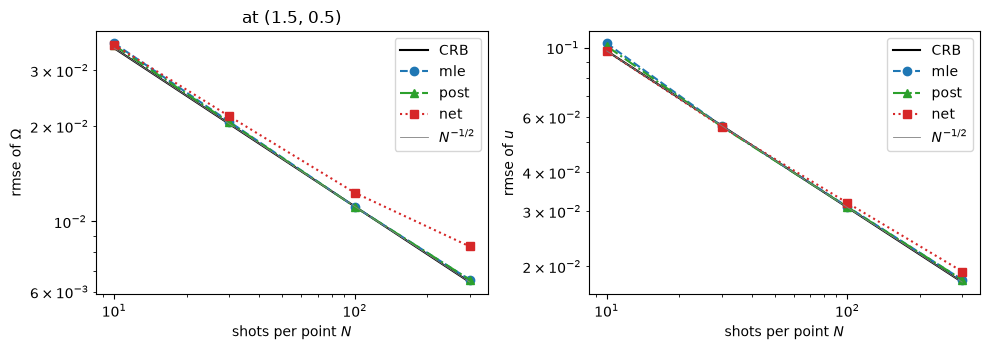

In [17]:
M7 = 2000
rng = np.random.default_rng(7)
pts = {k: [] for k in ['crb', 'mle', 'post', 'net']}
for N in Ns:
    n = rabi.simulate(OM0, DE0**2, M7, rng, N=N)
    true = np.array([OM0, DE0**2])
    rm = lambda est: np.sqrt(((np.stack(est[:2], 1) - true)**2).mean(0))
    pts['crb'].append(rabi.crb(OM0, DE0**2, N=N)); pts['mle'].append(rm(rabi.mle(n, N)))
    pts['post'].append(rm(rabi.posterior_mean(n, N))); pts['net'].append(rm(rabinet.predict(nets[N], n, N)))
pts = {k: np.array(v) for k, v in pts.items()}

print(f"rmse / CRB at (1.5, 0.5)   (MC error on each ratio ~ {1/np.sqrt(2*M7):.3f})")
print(f"{'N':>4}" + ''.join(f"{k + ' ' + p:>11}" for k in ['mle', 'post', 'net'] for p in ['Om', 'u']))
for i, N in enumerate(Ns):
    print(f"{N:>4}" + ''.join(f"{pts[k][i, p] / pts['crb'][i, p]:11.3f}" for k in ['mle', 'post', 'net'] for p in [0, 1]))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for a, p, lab in [(ax[0], 0, r'$\Omega$'), (ax[1], 1, '$u$')]:
    a.loglog(Ns, pts['crb'][:, p], 'k-', label='CRB')
    for k, sty in [('mle', 'C0o--'), ('post', 'C2^-.'), ('net', 'C3s:')]:
        a.loglog(Ns, pts[k][:, p], sty, label=k)
    a.loglog(Ns, pts['crb'][2, p] * np.sqrt(100 / np.array(Ns)), color='gray', lw=0.6, label=r'$N^{-1/2}$')
    a.set_xlabel('shots per point $N$'); a.set_ylabel(f'rmse of {lab}'); a.legend()
ax[0].set_title('at (1.5, 0.5)'); plt.tight_layout(); plt.show()

**Verdict on the predictions.**

1. **Held.** Averaged over the prior, the posterior mean beats both the network and the MLE at every $N$
   (16 checks above). The MLE's gap is largest at $N=10$ in $u$ ($27\%$ worse), which comes from the edges
   of the prior, where knowing the prior helps most.

2. **Failed.** At the interior point $(1.5,0.5)$ nothing beats the CRB by a wide margin, even at $N=10$: the
   posterior mean sits at $1.02$–$1.04\times$ the bound and the MLE at $1.04$–$1.06\times$. The reason is that
   "$N=10$" is not a small experiment. It is $24\times10=240$ shots, which pins $\Omega$ to $\pm0.035$ inside a
   prior of width 1. The prior only matters when the posterior is comparable to the prior's width or to
   the distance to an edge, and at $(1.5,0.5)$ it never is. To see the prior take over in the interior you
   would need a handful of shots in total.

3. **Not predicted.** The network gets *relatively worse* as $N$ grows: $1.03\times$ the CRB at $N=10$ but
   $1.30\times$ at $N=300$ in $\Omega$, and its prior-averaged risk is twice the posterior's at $N=300$. This is the
   Step 5 error floor again. The same recipe reaches roughly the same absolute accuracy (about $0.008$ in
   $\Omega$) whatever $N$ is, so the more informative the data, the more the network leaves on the table. A
   network that keeps up with the bound needs capacity and training that grow with $N$.

## Summary of checks

In [18]:
for name, ok in CHECKS: print(f"{'PASS' if ok else 'FAIL'}  {name}")
print(f"\n{sum(ok for _, ok in CHECKS)}/{len(CHECKS)} passed")

PASS  analytic gradient vs finite differences
PASS  CRB reference values
PASS  Fisher info for Delta vanishes at Delta=0, for u it does not
PASS  CRB scales as 1/sqrt(N)
PASS  MLE std / CRB = 1 for Om at (1.5, 0.5)
PASS  MLE unbiased for Om at (1.5, 0.5)
PASS  MLE std / CRB = 1 for u at (1.5, 0.5)
PASS  MLE unbiased for u at (1.5, 0.5)
PASS  |De| MLE "beats" its CRB at (1.5, 0.05)
PASS  ...because |De| MLE is biased upward
PASS  u MLE "beats" its CRB at (1.5, 0.05)
PASS  ...because u MLE is biased upward
PASS  signed Delta head outputs ~0 everywhere (sign is invisible)
PASS  network does not beat the CRB in the interior (Om)
PASS  network does not beat the CRB in the interior (u)
PASS  network within 25% of the CRB in the interior
PASS  MLE likelihood >= likelihood at the truth, on every dataset
PASS  every sub-CRB variance of the network comes with significant bias
PASS  prior-averaged: posterior <= net, N=10, Om
PASS  prior-averaged: posterior <= mle, N=10, Om
PASS  prior-averaged: p